# HW7P5 — Unsupervised learning exploration

**Your name:**

Build a pipeline that performs k-means clustering and PCA on a real dataset, reports silhouette scores, visualizes clusters in 2D, and interprets what the clusters represent. Complete each `TODO` section.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

## Task 1: Data and preprocessing

TODO: load, select numeric features, handle missing values, scale.

In [3]:
# TODO
from sklearn.datasets import load_breast_cancer
data = load_breast_cancer()
print(data.feature_names)
X = pd.DataFrame(data.data, columns=data.feature_names)

X = X.fillna(X.mean())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']


## Task 2: k-means and silhouette scores

TODO: at least three values of k; justify your choice.

In [9]:
# TODO
k_values = [2, 3, 4]
silhouette_scores = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42)
    cluster_labels = kmeans.fit_predict(X_scaled)
    silhouette_avg = silhouette_score(X_scaled, cluster_labels)
    silhouette_scores.append(silhouette_avg)
    print(f"For k={k}, silhouette score: {silhouette_avg}")

print("Best k:", k_values[silhouette_scores.index(max(silhouette_scores))])

For k=2, silhouette score: 0.3447344346611054
For k=3, silhouette score: 0.3151862330494096
For k=4, silhouette score: 0.27415774203442206
Best k: 2


## Task 3: PCA and a 2D plot

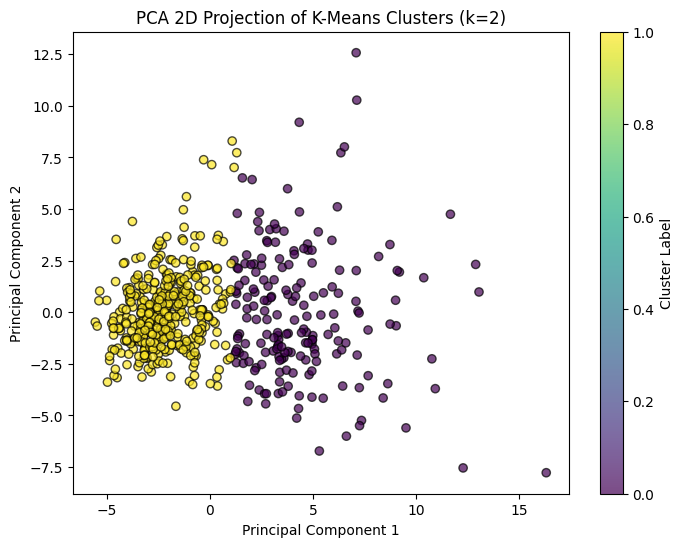

In [10]:
# TODO
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

optimal_kmeans = KMeans(n_clusters=2, random_state=42)
cluster_labels = optimal_kmeans.fit_predict(X_scaled)

plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_labels, cmap='viridis', edgecolor='k', alpha=0.7)
plt.title("PCA 2D Projection of K-Means Clusters (k=2)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label='Cluster Label')
plt.show()

## Task 4: Interpretation

TODO: what does each cluster represent? One reason the clusters might not be meaningful.
The two cluster represent benign and malignant tumors. The unsupervised model can be sensitive to outliers or feature scaling choices, and may not perfectly align with medical classifications.

## AI use disclosure

TODO: which AI tools (if any) you used and what you checked or changed. Write "None" if you did not use AI.
I used gemini, and checked k-means evaluation and PCA visualization.